# 01. BLUP по таблице связей


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Отчёт считает прогнозную оценку качества изделия **только по таблице связей** (матрица A), без маркерной панели.

| | |
|---|---|
| **Данные** | `data/lineage.csv`, `data/measurements.csv` |
| **Цель** | Собрать матрицы A, X, Z и получить оценку через `mixed.solve` |
| **Результат** | Оценка, стандартная ошибка и reliability для каждого `item_id` |


In [2]:
library(rrBLUP)
library(AGHmatrix)
library(Matrix)
library(pedigreeTools)
library(dplyr)
library(ggplot2)
library(tidyr)
library(stringr)
library(e1071)
library(knitr)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Attaching package: ‘tidyr’



The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack



In [3]:
z_score_filter <- function(pipeline, threshold) {
  z <- abs((pipeline$trait - mean(pipeline$trait, na.rm = TRUE)) / sd(pipeline$trait, na.rm = TRUE))
  pipeline %>% filter(!(z > threshold))
}

bending <- function(matrix, epsilon) {
  e <- eigen(matrix)
  e$values[e$values < epsilon] <- epsilon
  out <- e$vectors %*% diag(e$values) %*% t(e$vectors)
  rownames(out) <- rownames(matrix)
  colnames(out) <- colnames(matrix)
  out
}

scale_g_to_a <- function(A_matrix, G_matrix) {
  common <- intersect(rownames(G_matrix), rownames(A_matrix))
  G_matrix <- G_matrix[common, common, drop = FALSE]
  A22 <- A_matrix[common, common, drop = FALSE]
  G_matrix * (sum(diag(A22)) / sum(diag(G_matrix)))
}

prepare_ids <- function(lineage, measurements, markers = NULL) {
  ids <- unique(c(measurements$item_id, lineage$item_id, lineage$parent_a, lineage$parent_b))
  if (!is.null(markers)) ids <- unique(c(ids, markers$item_id))
  ids <- ids[ids != 0]
  levels <- as.character(sort(unique(ids)))
  recode <- function(x) as.integer(factor(as.character(x), levels = levels))
  lineage <- lineage %>%
    mutate(
      item_id = recode(item_id),
      parent_a = ifelse(parent_a == 0, 0L, recode(parent_a)),
      parent_b = ifelse(parent_b == 0, 0L, recode(parent_b))
    )
  measurements <- measurements %>% mutate(item_id = recode(item_id))
  if (!is.null(markers)) {
    markers <- markers %>% mutate(item_id = recode(item_id))
  }
  list(lineage = lineage, measurements = measurements, markers = markers, levels = levels)
}

order_lineage <- function(lineage, keep_ids) {
  ped <- editPed(label = lineage$item_id, sire = lineage$parent_a, dam = lineage$parent_b)
  ped <- ped[, c("label", "sire", "dam")]
  names(ped) <- c("item_id", "parent_a", "parent_b")
  ped <- ped %>% filter(item_id %in% keep_ids)
  ped$parent_a[!(ped$parent_a %in% ped$item_id)] <- 0
  ped$parent_b[!(ped$parent_b %in% ped$item_id)] <- 0
  rownames(ped) <- ped$item_id
  ped
}


# 1. Данные

Связи — кто от какой предыдущей позиции линии произошёл (`parent_a`, `parent_b`). Измерения — `trait` и фиксированные эффекты партии.


In [4]:
measurements <- read.csv("data/measurements.csv") %>%
  dplyr::select(item_id, batch_mass, batch_no, line_age, event_season, event_year, trait)
lineage <- read.csv("data/lineage.csv")
head(lineage)
head(measurements)


  item_id parent_a parent_b
1       1        0        0
2       2        0        0
3       3        0        0
4       4        0        0
5       5        0        0
6       6        0        0


  item_id batch_mass   batch_no    line_age event_season event_year      trait
1       1  0.5743562  0.6679681 -0.52938589       spring       2024 -1.9893504
2       2 -0.2307000 -0.0131677 -0.47078697       spring       2022 -0.6812021
3       3  1.1722425  0.7760470 -1.54593692       winter       2024 -1.1351831
4       4  1.3927027 -2.0107353 -0.04052672       spring       2023  2.1441626
5       5 -0.6619913 -1.1281805  0.89035631       spring       2024 -1.6362739
6       6 -0.7773692  0.3487996 -2.07138785       spring       2024 -0.4870425


# 2. Очистка и синхронизация


In [5]:
measurements <- z_score_filter(measurements, 2) %>% drop_na()
lineage <- lineage %>%
  filter(item_id %in% measurements$item_id | parent_a %in% measurements$item_id | parent_b %in% measurements$item_id)
measurements <- measurements %>% filter(item_id %in% lineage$item_id)
prep <- prepare_ids(lineage, measurements)
lineage_bl <- order_lineage(prep$lineage, prep$measurements$item_id)
meas_bl <- prep$measurements %>%
  mutate(
    event_season = factor(event_season),
    event_year = factor(event_year)
  )
c(n_items = nrow(meas_bl), n_links = nrow(lineage_bl))


n_items n_links 
    190     190 


# 3. Матрицы

A — коэффициенты сходства по связям. X — фиксированные эффекты. Z — инцидентность изделия.


In [6]:
A <- Amatrix(lineage_bl[, c("item_id", "parent_a", "parent_b")], ploidy = 2)
if (nrow(A) == nrow(lineage_bl)) {
  rownames(A) <- as.character(lineage_bl$item_id)
  colnames(A) <- as.character(lineage_bl$item_id)
} else {
  rownames(A) <- as.character(rownames(A))
  colnames(A) <- as.character(colnames(A))
}
A[1:5, 1:5]


Verifying conflicting data... 
Organizing data... 
Your data was chronologically organized with success. 
Constructing matrix A using ploidy = 2 
Completed! Time = 1e-04  minutes 


  1 2 3 4 5
1 1 0 0 0 0
2 0 1 0 0 0
3 0 0 1 0 0
4 0 0 0 1 0
5 0 0 0 0 1


In [7]:
meas_bl <- meas_bl[as.character(meas_bl$item_id) %in% rownames(A), ]
meas_bl <- meas_bl[order(match(as.character(meas_bl$item_id), rownames(A))), ]
X <- model.matrix(~ line_age + batch_mass + batch_no + event_season + event_year, data = meas_bl)
Z <- model.matrix(~ 0 + factor(item_id, levels = rownames(A)), data = meas_bl)
colnames(Z) <- rownames(A)
cat("Rank X:", qr(X)$rank, "of", ncol(X), "\n")
dim(A); dim(X); dim(Z)


Rank X: 9 of 9 


[1] 190 190


[1] 190   9


[1] 190 190


# 4. mixed.solve


In [8]:
res <- mixed.solve(y = meas_bl$trait, X = X, Z = Z, K = A)
est <- res$u
A_inv <- solve(A + diag(1e-6, nrow(A)))
se <- sqrt(res$Vu * diag(A_inv))
solutions <- data.frame(
  item_id = prep$levels[as.integer(names(est))],
  estimate = as.numeric(est),
  se = as.numeric(se[names(est)]),
  stringsAsFactors = FALSE
)
solutions$reliability <- 1 - (solutions$se^2 / res$Vu)
head(solutions, 8)


  item_id      estimate           se reliability
1       1  1.782789e-10 7.443362e-05  -1.4999900
2       2  1.356258e-09 8.827368e-05  -2.5161103
3       3 -1.208023e-09 7.924062e-05  -1.8333211
4       4  9.988872e-10 5.765608e-05  -0.4999965
5       5 -1.233821e-09 8.807099e-05  -2.4999815
6       6 -1.234008e-09 8.807098e-05  -2.4999810
7       7  1.452832e-09 5.765608e-05  -0.4999965
8       8  8.979576e-10 5.765608e-05  -0.4999965


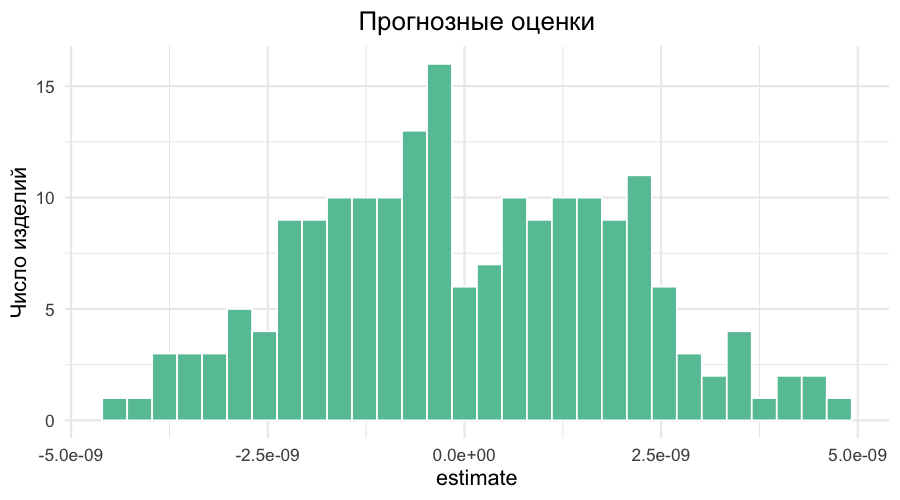

In [9]:
ggplot(solutions, aes(x = estimate)) +
  geom_histogram(bins = 30, fill = "#66C2A5", color = "white") +
  labs(title = "Прогнозные оценки", x = "estimate", y = "Число изделий") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


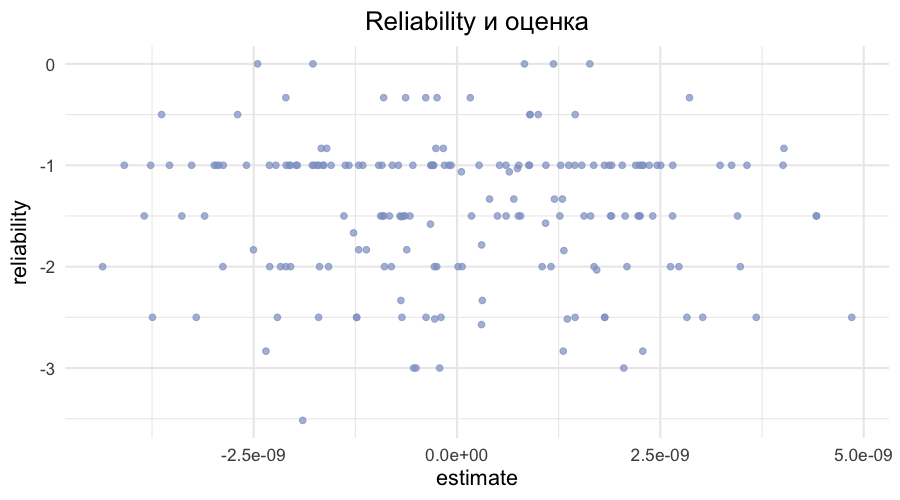

In [10]:
ggplot(solutions, aes(x = estimate, y = reliability)) +
  geom_point(alpha = 0.7, color = "#8DA0CB") +
  labs(title = "Reliability и оценка", x = "estimate", y = "reliability") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# Заключение

По таблице связей смешанная модель даёт оценку качества даже для изделий без маркерной панели: родственные позиции «делятся» информацией. Reliability падает там, где мало измерений и слабые связи — такие строки нельзя сравнивать с хорошо оценёнными наравне.
